In [7]:
import pandas as pd
import joblib
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd

# Load test dataset
test_df = pd.read_csv("../data/testing.csv")

# Remove rows where target is missing
test_df = test_df.dropna(subset=["Churn"]).copy()

# Separate features and target
X_test = test_df.drop(columns=["CustomerID", "Churn"])
y_test = test_df["Churn"].astype(int)

print("Test features shape:", X_test.shape)
print("Test target shape:", y_test.shape)


Test features shape: (64374, 10)
Test target shape: (64374,)


In [11]:
# Load original training dataset
train_df = pd.read_csv("../data/training.csv")

# Remove rows with missing target
train_df = train_df.dropna(subset=["Churn"]).copy()

# Calculate thresholds from training data only
usage_threshold = train_df["Usage Frequency"].median()
tenure_threshold = train_df["Tenure"].median()
support_threshold = train_df["Support Calls"].median()
delay_threshold = train_df["Payment Delay"].median()

print("Feature engineering thresholds:")
print("Usage:", usage_threshold)
print("Tenure:", tenure_threshold)
print("Support Calls:", support_threshold)
print("Payment Delay:", delay_threshold)

Feature engineering thresholds:
Usage: 16.0
Tenure: 32.0
Support Calls: 3.0
Payment Delay: 12.0


In [16]:
# ==========================================
# FEATURE ENGINEERING FOR TEST DATA
# ==========================================

# 1. Load original training data
train_df = pd.read_csv("../data/training.csv")

# Remove rows with missing target
train_df = train_df.dropna(subset=["Churn"]).copy()

# 2. Calculate thresholds from training data only
usage_threshold = train_df["Usage Frequency"].median()
tenure_threshold = train_df["Tenure"].median()
support_threshold = train_df["Support Calls"].median()
delay_threshold = train_df["Payment Delay"].median()


# 3. Define feature engineering function
def add_features(data):

    data = data.copy()

    data["Usage_Tenure_Interaction"] = (
        data["Usage Frequency"] * data["Tenure"]
    )

    data["Support_Payment_Risk"] = (
        data["Support Calls"] * data["Payment Delay"]
    )

    data["Low_Usage_Low_Tenure"] = (
        (data["Usage Frequency"] < usage_threshold) &
        (data["Tenure"] < tenure_threshold)
    ).astype(int)

    data["High_Support_High_Delay"] = (
        (data["Support Calls"] > support_threshold) &
        (data["Payment Delay"] > delay_threshold)
    ).astype(int)

    return data


# 4. Apply feature engineering to test data
X_test_fe = add_features(X_test)

print("Feature engineering completed!")
print("Original features:", X_test.shape[1])
print("Feature-engineered features:", X_test_fe.shape[1])

display(X_test_fe.iloc[:, -4:].head())

Feature engineering completed!
Original features: 10
Feature-engineered features: 14


,Usage_Tenure_Interaction,Support_Payment_Risk,Low_Usage_Low_Tenure,High_Support_High_Delay
0,350,108,1,1
1,784,91,0,1
2,270,58,1,0
3,108,85,1,1
4,1392,18,0,0


In [20]:
# Load baseline Logistic Regression
logistic_model = joblib.load(
    "../models/logisticRE_model.pkl"
)

# Load Feature-Engineered Logistic Regression
logistic_fe_model = joblib.load(
    "../models/logisticRE_fe_model.pkl"
)

print("Both Logistic Regression models loaded successfully!")

Both Logistic Regression models loaded successfully!


In [21]:
models = {
    "Logistic Regression": (logistic_model, X_test),
    "Logistic Regression (Feature Engineered)": (
        logistic_fe_model, X_test_fe
    )
}

logistic_results = []

for name, (model, features) in models.items():

    y_pred = model.predict(features)
    y_prob = model.predict_proba(features)[:, 1]

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    logistic_results.append(results)

logistic_results_df = pd.DataFrame(logistic_results)

display(logistic_results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.571193,0.525112,0.990588,0.686375,0.689440
1,Logistic Regression (Feature Engineered),0.567993,0.523261,0.989637,0.684565,0.666112


In [22]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred_lr = logistic_model.predict(X_test)

print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

[[ 6564 27317]
 [  287 30206]]
              precision    recall  f1-score   support

           0       0.96      0.19      0.32     33881
           1       0.53      0.99      0.69     30493

    accuracy                           0.57     64374
   macro avg       0.74      0.59      0.50     64374
weighted avg       0.75      0.57      0.49     64374



In [23]:
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Try different thresholds
for threshold in [0.5, 0.6, 0.7, 0.8, 0.9]:

    y_pred_threshold = (y_prob_lr >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred_threshold))

    print(classification_report(
        y_test,
        y_pred_threshold,
        zero_division=0
    ))


Threshold: 0.5
Confusion Matrix:
[[ 6564 27317]
 [  287 30206]]
              precision    recall  f1-score   support

           0       0.96      0.19      0.32     33881
           1       0.53      0.99      0.69     30493

    accuracy                           0.57     64374
   macro avg       0.74      0.59      0.50     64374
weighted avg       0.75      0.57      0.49     64374


Threshold: 0.6
Confusion Matrix:
[[ 7666 26215]
 [  446 30047]]
              precision    recall  f1-score   support

           0       0.95      0.23      0.37     33881
           1       0.53      0.99      0.69     30493

    accuracy                           0.59     64374
   macro avg       0.74      0.61      0.53     64374
weighted avg       0.75      0.59      0.52     64374


Threshold: 0.7
Confusion Matrix:
[[ 8949 24932]
 [  731 29762]]
              precision    recall  f1-score   support

           0       0.92      0.26      0.41     33881
           1       0.54      0.98      0.7

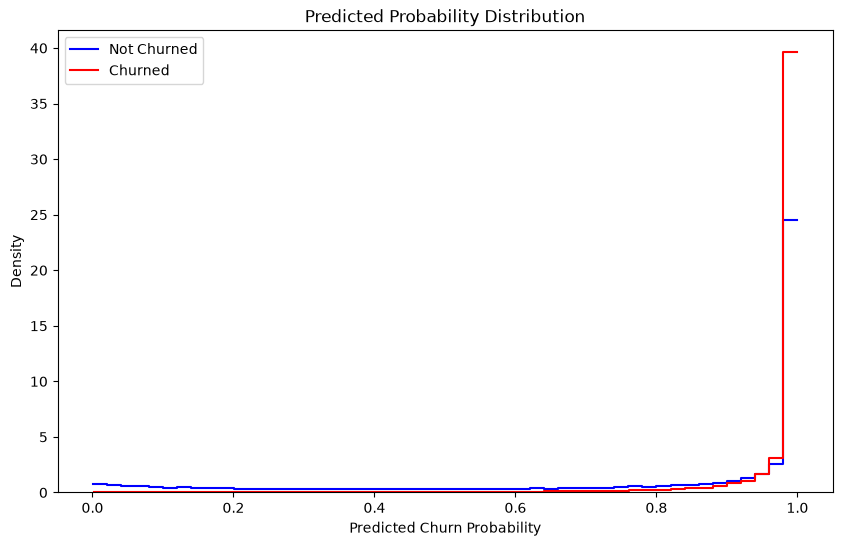

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    y_prob_lr[y_test == 0],
    bins=50,
    color="blue",
    label="Not Churned",
    stat="density",
    element="step",
    fill=False
)

sns.histplot(
    y_prob_lr[y_test == 1],
    bins=50,
    color="red",
    label="Churned",
    stat="density",
    element="step",
    fill=False
)

plt.xlabel("Predicted Churn Probability")
plt.ylabel("Density")
plt.title("Predicted Probability Distribution")
plt.legend()
plt.show()

In [25]:
import pandas as pd
import numpy as np

probability_analysis = pd.DataFrame({
    "Actual_Churn": y_test,
    "Predicted_Probability": y_prob_lr
})

for churn_class in [0, 1]:

    probabilities = probability_analysis.loc[
        probability_analysis["Actual_Churn"] == churn_class,
        "Predicted_Probability"
    ]

    print(f"\nActual Churn Class: {churn_class}")

    print(probabilities.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ))

    print(
        "Probability >= 0.99:",
        (probabilities >= 0.99).sum()
    )


Actual Churn Class: 0
count    33881.000000
mean         0.790179
std          0.310870
min          0.000544
25%          0.666587
50%          0.977068
75%          0.999925
90%          0.999999
95%          1.000000
99%          1.000000
max          1.000000
Name: Predicted_Probability, dtype: float64
Probability >= 0.99: 15059

Actual Churn Class: 1
count    30493.000000
mean         0.970446
std          0.089418
min          0.002843
25%          0.987156
50%          0.999248
75%          0.999999
90%          1.000000
95%          1.000000
99%          1.000000
max          1.000000
Name: Predicted_Probability, dtype: float64
Probability >= 0.99: 22126


In [26]:
# Extract the fitted preprocessing and classifier
preprocessor_fitted = logistic_model.named_steps["preprocessor"]
classifier = logistic_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Extract coefficients
coefficients = classifier.coef_[0]

# Create a DataFrame
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print(coefficient_df.head(20))

                            Feature  Coefficient  Absolute_Coefficient
13     cat__Contract Length_Monthly     7.431561              7.431561
14   cat__Contract Length_Quarterly    -2.776779              2.776779
12      cat__Contract Length_Annual    -2.765281              2.765281
3                num__Support Calls     2.299895              2.299895
7                cat__Gender_Female     1.519107              1.519107
5                  num__Total Spend    -1.455885              1.455885
4                num__Payment Delay     0.923679              0.923679
9      cat__Subscription Type_Basic     0.709278              0.709278
11  cat__Subscription Type_Standard     0.590379              0.590379
10   cat__Subscription Type_Premium     0.589843              0.589843
6             num__Last Interaction     0.524637              0.524637
0                          num__Age     0.444628              0.444628
8                  cat__Gender_Male     0.370393              0.370393
1     

In [28]:

# Extract the fitted preprocessing and classifier
preprocessor_fitted = logistic_fe_model.named_steps["preprocessor"]
classifier = logistic_fe_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Extract coefficients
coefficients = classifier.coef_[0]

# Create a DataFrame
coefficient_df_fe = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
coefficient_df_fe["Absolute_Coefficient"] = (
    coefficient_df_fe["Coefficient"].abs()
)

coefficient_df_fe = coefficient_df_fe.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

# Display top 20 features
print(coefficient_df_fe.head(20))


                            Feature  Coefficient  Absolute_Coefficient
17     cat__Contract Length_Monthly     7.762116              7.762116
18   cat__Contract Length_Quarterly    -2.930341              2.930341
16      cat__Contract Length_Annual    -2.918215              2.918215
3                num__Support Calls     2.888563              2.888563
11               cat__Gender_Female     1.529167              1.529167
5                  num__Total Spend    -1.461987              1.461987
4                num__Payment Delay     1.277200              1.277200
8         num__Support_Payment_Risk    -1.006499              1.006499
13     cat__Subscription Type_Basic     0.722199              0.722199
15  cat__Subscription Type_Standard     0.596788              0.596788
14   cat__Subscription Type_Premium     0.594573              0.594573
6             num__Last Interaction     0.524371              0.524371
0                          num__Age     0.437941              0.437941
12    